# Frente B: de la señal limpia a la tabla de descriptores (etapas 6 a 9)

Este notebook cuenta el recorrido completo del Frente B y arma la tabla que recibe el
Frente C. Cada técnica tiene su propio capítulo, con el detalle de qué se le hace a la
señal y por qué.

| Capítulo | Notebook | Señal | Qué mide | Estadio que delata |
|---|---|---|---|---|
| 1. Espectro | `02a_frente_B_espectro` | Los 4 EEG | Potencia de cada ritmo y pendiente del espectro | Todos, sobre todo W y N3 |
| 2. Husos | `02b_frente_B_husos` | EEG central (C4) | Ráfagas de 11 a 16 Hz | N2 |
| 3. Ondas lentas y Woody | `02c_frente_B_ondas_lentas_woody` | EEG frontal (F4) | Ondas grandes de menos de 4 Hz y su forma | N3 |
| 4. CSP | `02d_frente_B_csp` | Los 4 EEG combinados | Diferencias entre zonas del cerebro | N1 frente a REM |
| 5. EOG y EMG | `02e_frente_B_eog_emg` | EOG y EMG de mentón | Movimientos oculares y tono muscular | REM y W |

## La historia en una figura

```
                         Frente A                 Frente B                          Frente C
Registro crudo ──► RegistroPreprocesado ──► TablaDescriptores ──────────────► hipnograma
                   señales limpias, en µV     una fila por época de 30 s
                                              ├─ espectro.*     (56)   cap. 1
                                              ├─ husos.*        (2)    cap. 2
                                              ├─ ondas.*        (3)    cap. 3
                                              ├─ perifericos.*  (2)    cap. 5
                                              ├─ hrv.*          (lo calcula el Frente A)
                                              └─ covarianzas    (4×4)  cap. 4, para CSP
```

El Frente B no clasifica: **mide**. Toma cada época de 30 s y la resume en unos 60
números que describen lo que el manual AASM mira para decidir el estadio, como los
ritmos del EEG, los husos, las ondas lentas, los movimientos oculares y el tono
muscular. La decisión la toma el Frente C con esos números.

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base (el primero que
haya descargado, en orden). Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian. Mientras el Frente A no esté
implementado, las señales llegan **crudas**: sin filtrar y sin quitar los artefactos.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.contratos import RegistroPreprocesado
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    crudo = cargar_registro(ids_disponibles()[0])
    try:
        prep = preprocesar(crudo, Config().preprocesamiento)
    except NotImplementedError:
        # Mientras el Frente A no esté, se trabaja sobre la señal cruda. Las funciones
        # del Frente B filtran por su cuenta en la banda que les interesa.
        print("El Frente A todavía no está: se usa la señal cruda.")
        prep = RegistroPreprocesado(
            crudo,
            latidos=np.array([], dtype=int),
            no_estacionaria=np.zeros(crudo.n_epocas, dtype=bool),
        )
else:
    prep = preprocesado_sintetico(minutos=120)

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

El Frente A todavía no está: se usa la señal cruda.
SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. La señal que entra

Una época de 30 s es la unidad de todo el trabajo: los técnicos le asignan un estadio,
y el Frente B le calcula sus descriptores. Este es el hipnograma de los técnicos para
el registro, la secuencia de estadios de toda la noche.

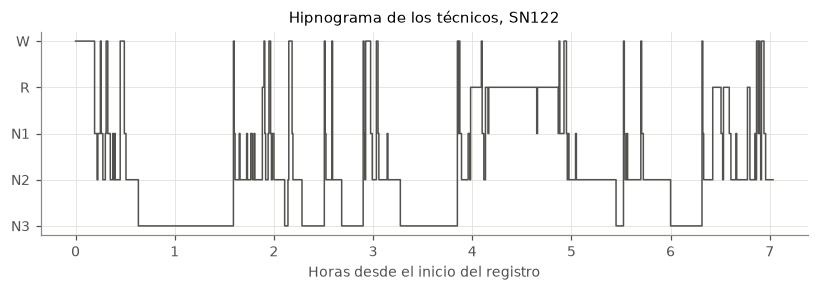

In [4]:
orden = ["N3", "N2", "N1", "R", "W"]
nivel = np.array([orden.index(NOMBRES_ESTADIOS[e]) if e >= 0 else np.nan for e in estadios_tecnicos])
horas = np.arange(registro.n_epocas) * 30 / 3600

fig, ax = plt.subplots(figsize=(9, 2.4))
ax.step(horas, nivel, where="post", color=TINTA, lw=1)
ax.set(yticks=range(len(orden)), yticklabels=orden, xlabel="Horas desde el inicio del registro",
       title=f"Hipnograma de los técnicos, {registro.id}")
guardar(fig, "b_hipnograma_tecnicos")

Y esto es lo que el Frente B recibe de una época: las ocho señales de la
polisomnografía durante 30 s. Se muestra una época de N2.

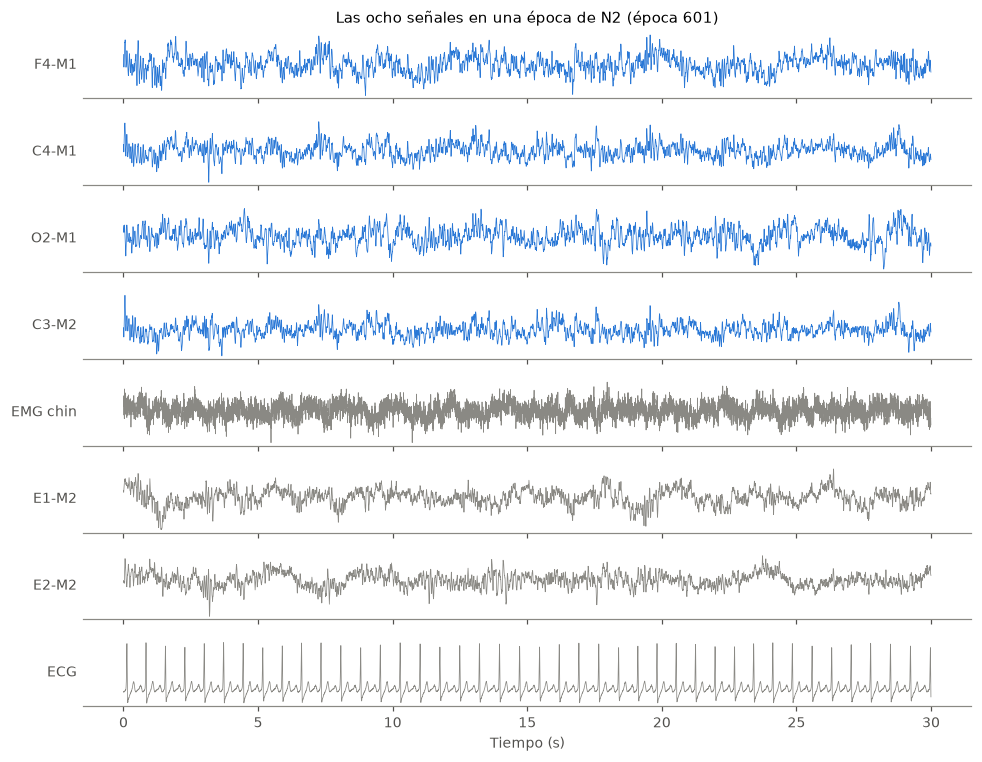

In [5]:
from estadios.comun.constantes import CANALES, N2

epocas_n2 = np.flatnonzero(estadios_tecnicos == N2)
j = epocas_n2[len(epocas_n2) // 2]
n_epoca = int(30 * fs)
tramo = slice(j * n_epoca, (j + 1) * n_epoca)
t = np.arange(n_epoca) / fs

fig, axs = plt.subplots(len(CANALES), 1, figsize=(9, 7), sharex=True)
for ax, canal in zip(axs, CANALES):
    ax.plot(t, registro.senales[canal][tramo], color=AZUL if canal.startswith("EEG") else GRIS, lw=0.5)
    ax.set_ylabel(canal.replace("EEG ", "").replace("EOG ", ""), rotation=0, ha="right", va="center")
    ax.grid(False)
    ax.tick_params(labelleft=False, left=False)
    ax.spines["left"].set_visible(False)
axs[-1].set(xlabel="Tiempo (s)")
axs[0].set_title(f"Las ocho señales en una época de N2 (época {j})")
fig.tight_layout()
guardar(fig, "b_epoca_ocho_senales")

Los cuatro EEG (azul) son los que más información aportan, y cada capítulo los mira de
una manera distinta. El EOG y el EMG se usan sobre todo para REM. El ECG lo usa el
Frente A para detectar latidos y calcular la HRV.

## 2. La tabla de descriptores

`ensamblado.describir_registro()` llama a cada capítulo y junta sus resultados en una
`TablaDescriptores`: una fila por época, una columna por descriptor, más las
covarianzas para CSP. Acá se arma la tabla con los grupos del Frente B.

**Descriptores de HRV (`hrv.*`).** Se completará cuando se complete A.

In [6]:
from estadios.descriptores import espectro, husos, ondas_lentas, perifericos

grupos = {
    "espectro": espectro.descriptores_espectrales(prep, cfg),
    "husos": husos.descriptores_husos(prep, cfg),
    "ondas": ondas_lentas.descriptores_ondas_lentas(prep, cfg),
    "perifericos": perifericos.descriptores_perifericos(prep, cfg),
}
matriz = np.hstack([m for m, _ in grupos.values()])
nombres = [n for _, ns in grupos.values() for n in ns]
print(f"{matriz.shape[0]} épocas × {matriz.shape[1]} descriptores")
for grupo, (_, ns) in grupos.items():
    print(f"  {grupo:12s} {len(ns):3d}")

845 épocas × 63 descriptores
  espectro      56
  husos          2
  ondas          3
  perifericos    2


## 3. Estandarizar dentro de cada noche

Los descriptores tienen escalas muy distintas: una potencia relativa va de 0 a 1, una
cantidad de husos de 0 a 10 y una pendiente es negativa. Además, el mismo descriptor
cambia de nivel de un paciente a otro por cosas que no tienen que ver con el sueño, como
la impedancia de los electrodos.

Por eso `estandarizar_por_registro()` lleva cada descriptor a media 0 y desvío 1
**dentro de cada noche**. Después de eso, un valor de +2 significa "dos desvíos por
encima de lo habitual para este paciente", sin importar la unidad ni el paciente.

La tabla muestra el promedio estandarizado de algunos descriptores en cada estadio: es
la "huella" que deja cada estadio en lo que mide el Frente B.

In [7]:
import pandas as pd
from estadios.descriptores.ensamblado import estandarizar_por_registro

z = estandarizar_por_registro(matriz)
elegidos = {
    "espectro.c4_delta_rel": "δ relativa (C4)",
    "espectro.o2_alfa_rel": "α relativa (O2)",
    "espectro.c4_pendiente": "Pendiente (C4)",
    "husos.cantidad": "Husos por época",
    "ondas.cantidad": "Ondas lentas por época",
    "perifericos.energia_eog": "Energía del EOG",
    "perifericos.amplitud_emg": "Amplitud del EMG",
}
huella = pd.DataFrame(
    {nombre: [z[estadios_tecnicos == e, nombres.index(clave)].mean() for clave in elegidos]
     for e, nombre in enumerate(NOMBRES_ESTADIOS) if (estadios_tecnicos == e).any()},
    index=list(elegidos.values()),
).round(2)
huella

,W,N1,N2,N3,R
δ relativa (C4),-1.37,-0.97,-0.43,1.03,-0.09
α relativa (O2),1.67,0.57,0.18,-0.77,0.16
Pendiente (C4),2.13,1.10,-0.17,-0.64,0.18
Husos por época,0.57,-0.22,0.46,-0.27,-0.69
Ondas lentas por época,-0.30,-0.58,-0.48,1.00,-0.68
Energía del EOG,0.65,-0.33,-0.68,0.13,1.22
Amplitud del EMG,1.83,0.80,-0.15,-0.14,-0.74


Cada estadio tiene su combinación. W tiene α, EMG y pendiente altos (un espectro más
plano). N3 tiene δ y ondas lentas muy por encima de lo habitual. REM tiene el EOG más
alto y el EMG más bajo de todos. N1 queda entre W y N2 en casi todo, y por eso es el
estadio más difícil: se reconoce más por lo que no tiene que por lo que tiene.

**Husos por época con la señal preprocesada.** Se completará cuando se complete A.

Esa tabla es, en resumen, lo que el Frente B le entrega al Frente C para decidir.